# Helper: Segment Anything (SAM 2) on the Project Tiles
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-F26/blob/main/Notebooks/SAM_Helper/SAM_Helper.ipynb)

**SAM** ("Segment Anything", Meta) cuts out a region of an image when you point at it. You click
on the water and get the whole bay; you draw a box round a field and get the field. It was trained on
11 million photos, and it needs **no labels from you**. That's transfer learning (L14) taken all the
way: nothing to train.

This notebook shows how to use it on our 1935–2020 air photos, using one coastal tile and one
farm tile. It's written for the **coastal** and **farm consolidation** groups, but anyone can use it.

| § | What |
|---|------|
| 1 | Setup and the tiles |
| 2 | Finding pixel coordinates to click on |
| 3 | One click: when it works, and when it doesn't |
| 4 | Fixing a mask: a box, plus "not this" clicks |
| 5 | The same prompt in 1935, 1968 and 2020: water area and shorelines |
| 6 | Checking a mask (IoU) |
| 7 | "Segment everything": counting fields, 1935 vs 2020 |
| 8 | Saving masks, areas and outlines |
| 9 | Practical tips |
| 10 | Swapping in SAM 3 (text prompts; needs approval and a GPU) |

**Runtime.** Use a GPU if you can (Colab: *Runtime → Change runtime type → T4 GPU*). On a CPU
everything still works: preparing an image takes about 9 s, each click after that well under a second,
and §7 (segment everything) about a minute per image.

**Your own tiles.** Every function below takes an image array, so you can use your group's PNGs from
Drive instead (§1 shows how). Results on *your* site will be different: check them (§6).

## 1 · Setup and the tiles

`ultralytics` (the YOLO package from L15) also runs SAM. It downloads the SAM 2 weights (160 MB)
from GitHub the first time; no account is needed.

In [2]:
import os, io, sys, time, zipfile, subprocess, urllib.request
os.environ["YOLO_VERBOSE"] = "False"          # keep the ultralytics package quiet (set before importing it)
try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    import ultralytics
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics.models.sam import SAM2Predictor

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU: everything works, just slower (see the timings printed below).")

ultralytics 8.4.208 | torch 2.15.0+cu132 | device cpu
No GPU: everything works, just slower (see the timings printed below).


The example tiles are 2048 × 2048 pixel crops at **1 m per pixel** (so 1 pixel = 1 m², and the crop
is about 2 × 2 km), cut from two project blocks:

* **Covehead** (coastal set 1): the inlet and Covehead Bay, 1935, 1968 and 2020;
* **Queen Road near Montague** (farm consolidation): fields, 1935, 1968 and 2020.

1935 and 1968 are grey; 2020 is colour.

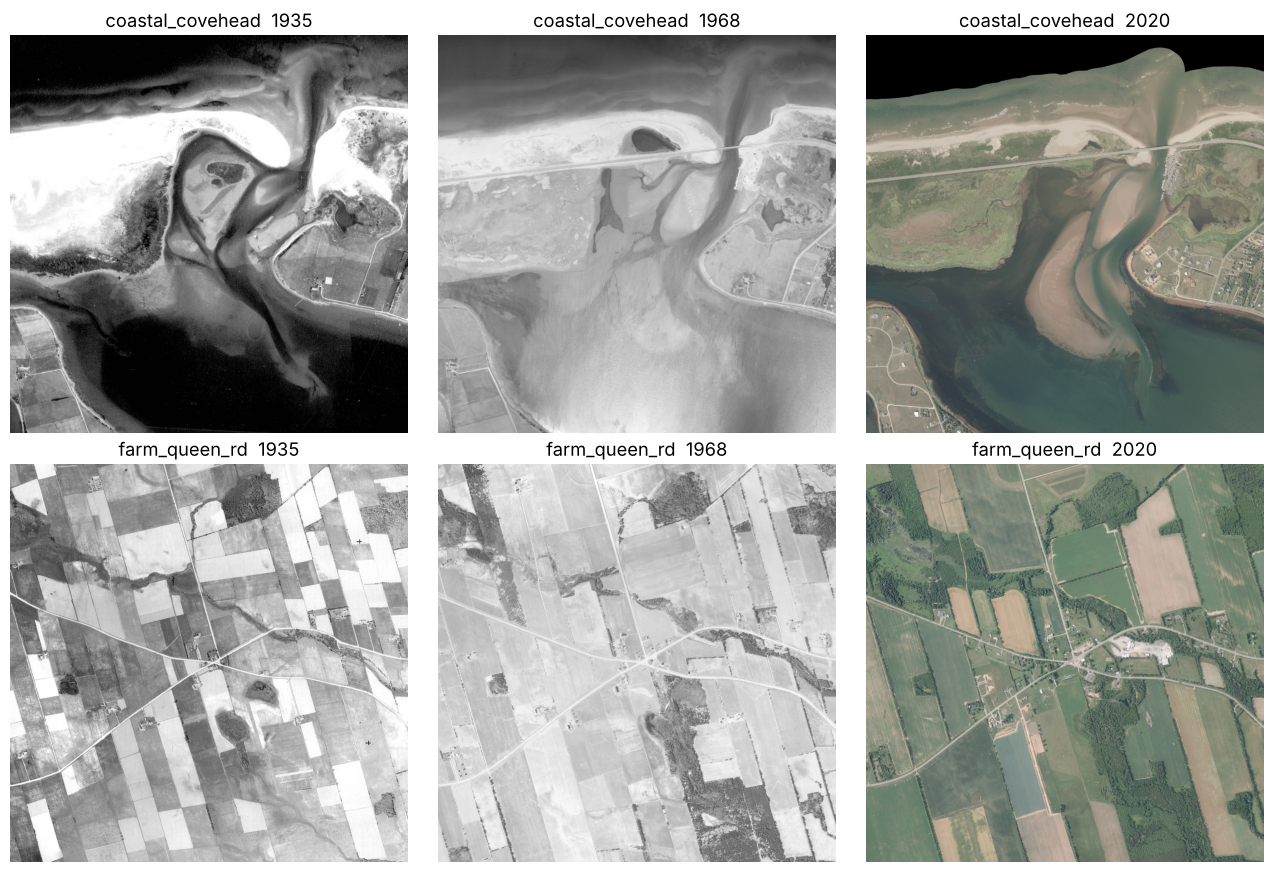

each tile: (2048, 2048, 3)


In [3]:
BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")
if not os.path.exists("sam_helper/farm_queen_rd_1935.png"):
    with urllib.request.urlopen(BASE + "SAM_helper.zip", timeout=180) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(".")
    print("SAM_helper.zip downloaded")

def load(path):
    '''Any image file -> H x W x 3 uint8 array in BGR order (what OpenCV and ultralytics use).
    Grey images are copied into all three channels.'''
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return img

def rgb(img):
    return img[..., ::-1]                      # BGR -> RGB, for showing with matplotlib

TILES = {}
for site in ("coastal_covehead", "farm_queen_rd"):
    for year in (1935, 1968, 2020):
        ext = "jpg" if year == 2020 else "png"
        TILES[site, year] = load(f"sam_helper/{site}_{year}.{ext}")

fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
for ax, ((site, year), img) in zip(axes.ravel(), TILES.items()):
    ax.imshow(rgb(img)); ax.set_title(f"{site}  {year}"); ax.axis("off")
plt.tight_layout(); plt.show()
print("each tile:", TILES["farm_queen_rd", 1935].shape)

**Using your own tile instead.** In Colab, mount Drive and load your group's PNG:

```python
from google.colab import drive
drive.mount("/content/drive")
img = load("/content/drive/MyDrive/<your folder>/stratford/1958.png")   # 3400 x 3000 at 1 m
```

Then use `img` wherever the cells below use `TILES[...]`. Read §9 first: SAM looks at every image at
1024 pixels across, so a whole 3400-pixel tile is seen at about 3.3 m per pixel.

## 2 · Finding pixel coordinates to click on

A prompt is given in **pixels of the original image**: `x` = column (left → right), `y` = row
(top → bottom), so (0, 0) is the top-left corner. The easiest way to pick points is a grid:

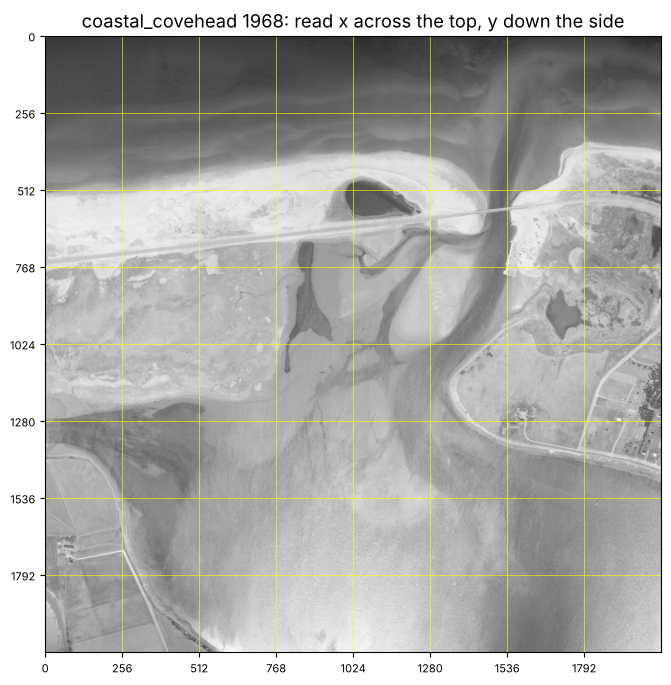

In [4]:
def show_grid(img, step=256, ax=None, title=""):
    ax = ax or plt.gca()
    ax.imshow(rgb(img))
    H, W = img.shape[:2]
    for v in range(0, W, step):
        ax.axvline(v, color="yellow", lw=0.6, alpha=0.7)
    for v in range(0, H, step):
        ax.axhline(v, color="yellow", lw=0.6, alpha=0.7)
    ax.set_xticks(range(0, W, step)); ax.set_yticks(range(0, H, step))
    ax.tick_params(labelsize=8); ax.set_title(title)

plt.figure(figsize=(8, 8))
show_grid(TILES["coastal_covehead", 1968], title="coastal_covehead 1968: read x across the top, y down the side")
plt.show()

## 3 · One click: when it works, and when it doesn't

SAM works in two steps:

1. **Encode the image once** (`set_image`): a big network turns the picture into features. This is
   the slow part (seconds on a CPU).
2. **Prompt as often as you like**: a small network turns each click or box into a mask, plus a
   **score** (SAM's own guess of how good the mask is, 0–1). This is fast.

So: one `set_image` per picture, then many prompts.

In [5]:
WEIGHTS = "sam2.1_b.pt"     # SAM 2.1 "base". Also: sam2.1_t.pt (tiny, faster), sam2.1_s.pt, sam2.1_l.pt (large)
predictor = SAM2Predictor(overrides=dict(model=WEIGHTS, task="segment", mode="predict",
                                         imgsz=1024, conf=0.0, save=False, verbose=False))

def set_image(img):
    t0 = time.time()
    predictor.set_image(img)
    return time.time() - t0

def segment(points=None, labels=None, box=None):
    '''One object from any mix of prompts on the current image.
    points: [(x, y), ...]   labels: 1 = "this", 0 = "not this"   box: (x1, y1, x2, y2)
    Returns (mask: H x W bool array, score).'''
    kw = {}
    if points:
        kw["points"] = [[list(p) for p in points]]          # nested list = all points describe ONE object
        kw["labels"] = [list(labels if labels is not None else [1] * len(points))]
    if box is not None:
        kw["bboxes"] = [list(box)]
    r = predictor(**kw)[0]
    return r.masks.data[0].cpu().numpy().astype(bool), float(r.boxes.conf[0])

def overlay(img, mask, ax, color=(0.1, 0.45, 1.0), alpha=0.55, points=(), labels=(), box=None, title=""):
    show = rgb(img).astype(float) / 255
    show[mask] = (1 - alpha) * show[mask] + alpha * np.array(color)
    ax.imshow(show)
    for (x, y), l in zip(points, labels):
        ax.plot(x, y, marker="*" if l else "X", ms=16, mec="white", mew=1.2, color="lime" if l else "red")
    if box is not None:
        x1, y1, x2, y2 = box
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow", lw=2))
    ax.set_title(title, fontsize=10); ax.axis("off")

def area_ha(mask, m_per_px=1.0):
    return mask.sum() * m_per_px ** 2 / 10_000           # 1 ha = 10,000 m²

The same single click, on the water of Covehead Bay, in three years:

1935: set_image 8.8 s, one click 0.18 s, score 0.54, area 149 ha


1968: set_image 8.0 s, one click 0.14 s, score 0.93, area 147 ha


2020: set_image 7.8 s, one click 0.15 s, score 0.70, area 348 ha


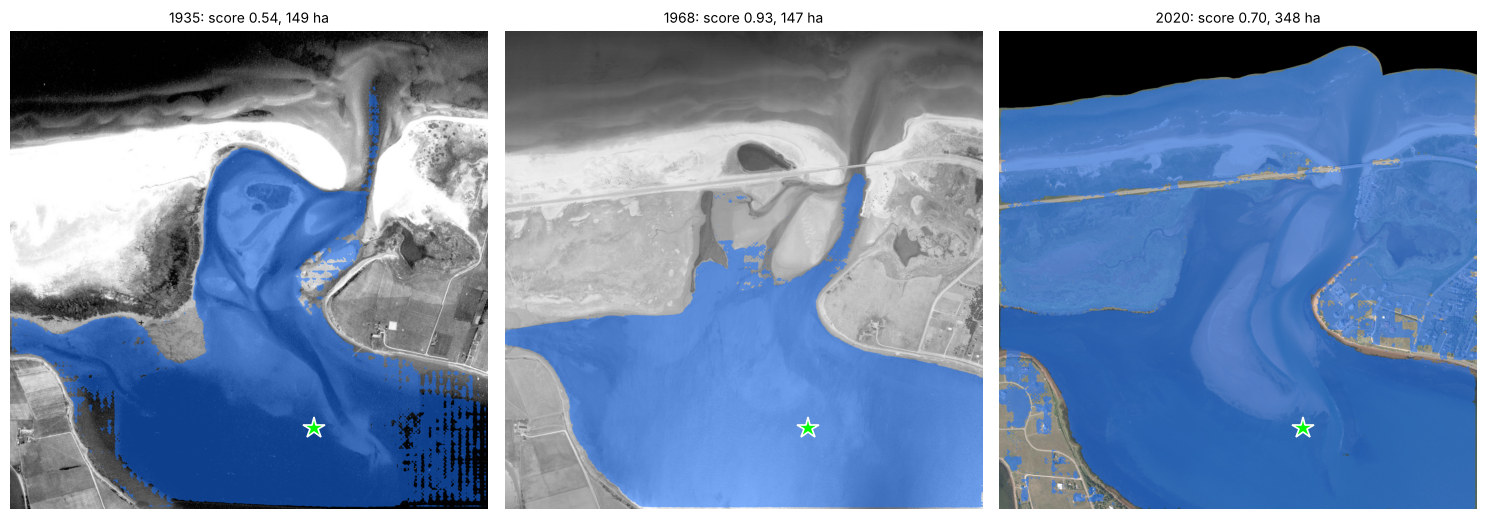

In [6]:
CLICK = (1300, 1700)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, year in zip(axes, (1935, 1968, 2020)):
    img = TILES["coastal_covehead", year]
    t = set_image(img)
    t0 = time.time(); mask, score = segment([CLICK], [1]); tp = time.time() - t0
    overlay(img, mask, ax, points=[CLICK], labels=[1],
            title=f"{year}: score {score:.2f}, {area_ha(mask):.0f} ha")
    print(f"{year}: set_image {t:.1f} s, one click {tp:.2f} s, score {score:.2f}, area {area_ha(mask):.0f} ha")
plt.tight_layout(); plt.show()

Read the three panels:

* **1968:** the bay, cleanly, with a high score. One click is enough.
* **2020:** most of the picture. SAM had to guess *which* thing you meant (the water? the water and
  the land it looks like? everything?) and guessed big. A single click is **ambiguous**.
* **1935:** the bay spills into the dark marsh and sand flats: in this print water and wet land have
  almost the same grey. The score is lower; **trust a low score less**.

The fix is to tell SAM more.

## 4 · Fixing a mask: a box, plus "not this" clicks

Three kinds of prompt, combinable for one object:

* **positive click** (label 1, green star): "part of it";
* **negative click** (label 0, red ✗): "not part of it";
* **box**: "it's inside here".

Here: a box over the lower half (the bay), one click in the water, and two "not this" clicks on land
(bottom-left fields and the east shore).

1935: score 0.81, water in the box 126 ha


1968: score 0.93, water in the box 137 ha


2020: score 0.93, water in the box 96 ha


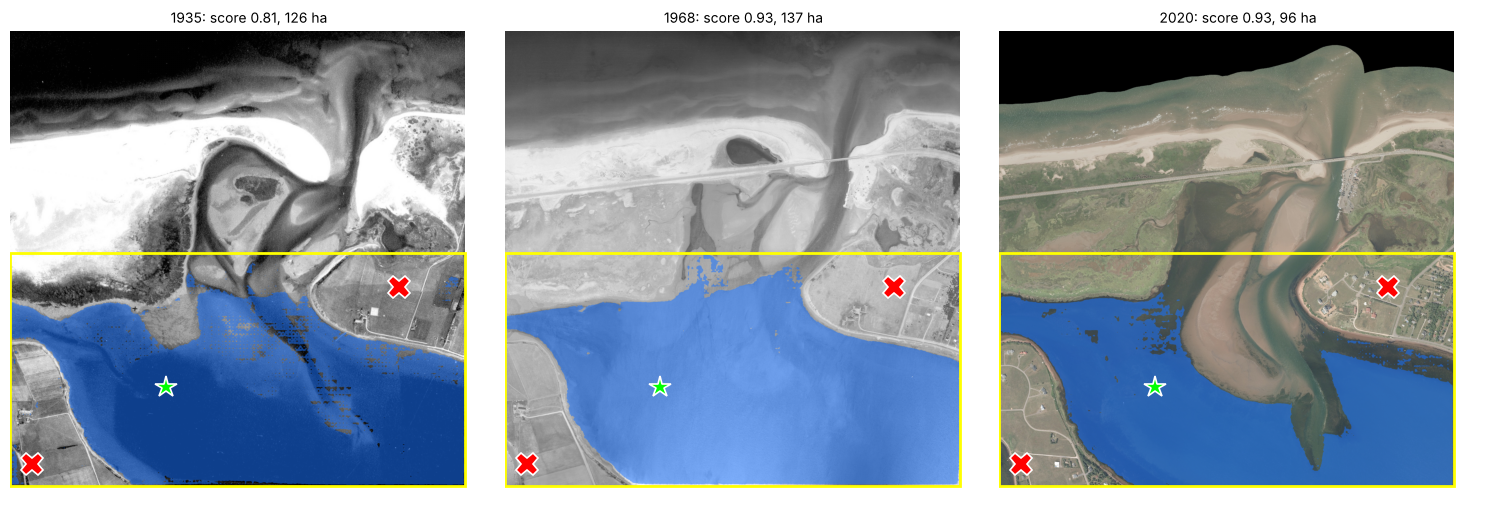

In [7]:
BOX = (0, 1000, 2048, 2048)
PTS = [(700, 1600), (100, 1950), (1750, 1150)]
LAB = [1, 0, 0]

WATER = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, year in zip(axes, (1935, 1968, 2020)):
    img = TILES["coastal_covehead", year]
    set_image(img)
    WATER[year], score = segment(PTS, LAB, box=BOX)
    overlay(img, WATER[year], ax, points=PTS, labels=LAB, box=BOX,
            title=f"{year}: score {score:.2f}, {area_ha(WATER[year]):.0f} ha")
    print(f"{year}: score {score:.2f}, water in the box {area_ha(WATER[year]):.0f} ha")
plt.tight_layout(); plt.show()

Better in every year, and the scores went up. Two things to notice, because they're decisions *you*
have to make, not SAM:

* **2020** leaves out the shallow, darker channel east of the big sand bar, and the bar itself. Is a
  tidal flat "water"? Decide on a rule for your project and apply it the same way every year.
* **1935** is still the weakest: look at the edges of the mask closely before you measure anything.

## 5 · The same prompt in 1935, 1968 and 2020: water area and shorelines

Because every year of a project block is on the **same 1 m grid**, the same prompt points to the same
place on the ground, and a pixel count is an area. Here are the three water outlines from §4 on top of
the 2020 photo.

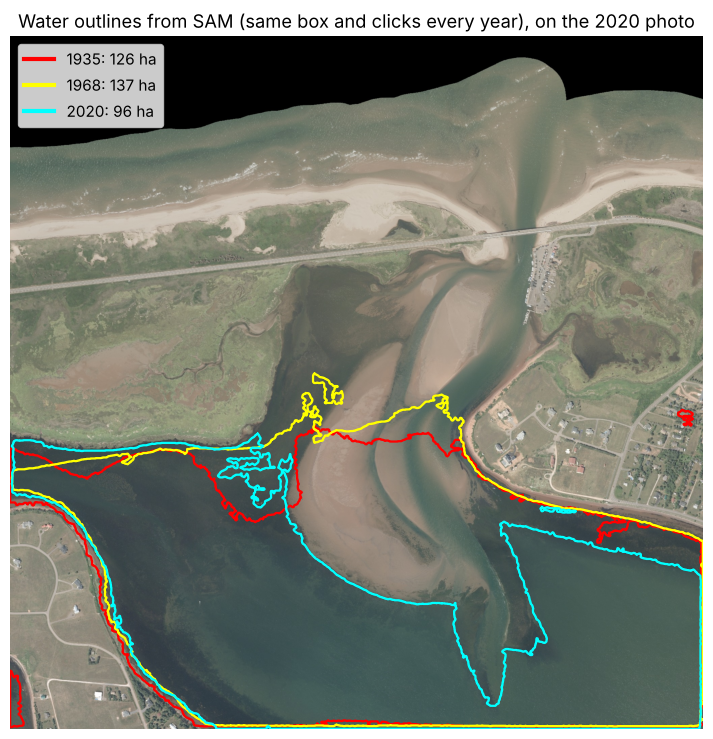

1935 -> 1968: water area 126 -> 137 ha (+11 ha)
1968 -> 2020: water area 137 -> 96 ha (-41 ha)


In [8]:
COL = {1935: "red", 1968: "yellow", 2020: "cyan"}
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(rgb(TILES["coastal_covehead", 2020]))
for year, m in WATER.items():
    contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in contours:
        if len(c) > 200:                                  # skip tiny specks
            ax.plot(c[:, 0, 0], c[:, 0, 1], color=COL[year], lw=1.6)
    ax.plot([], [], color=COL[year], lw=3, label=f"{year}: {area_ha(m):.0f} ha")
ax.legend(loc="upper left", fontsize=11); ax.axis("off")
ax.set_title("Water outlines from SAM (same box and clicks every year), on the 2020 photo")
plt.show()

for a, b in ((1935, 1968), (1968, 2020)):
    print(f"{a} -> {b}: water area {area_ha(WATER[a]):.0f} -> {area_ha(WATER[b]):.0f} ha "
          f"({area_ha(WATER[b]) - area_ha(WATER[a]):+.0f} ha)")

**Before you believe a change, list what else could cause it:**

* **Alignment.** Each historical year was matched to the 2000 photos; the typical leftover offset for
  this block is about **20 m in 1935**, 4 m in 1968 and 3.5 m in 2020 (from the block's build notes).
  A 20 m shift of a 2 km shoreline is several hectares. A shoreline "moving" less than the alignment
  error hasn't been shown to move.
* **Tide** on the day of the flight: flats that are under water at high tide are land at low tide.
* **The prompt and the rule** (§4): a mask that includes the sand flats in one year and not another is
  a measurement error, not erosion.
* **SAM's mistakes**, which you only find by checking (§6).

Here, most of 2020's −41 ha is the dark channel and sand bar that SAM left out (§4), not lost water.
Compare the outlines, not just the totals.

## 6 · Checking a mask (IoU)

Use L15's **IoU** (intersection over union), now on pixels instead of boxes: the pixels both masks
call "water", divided by the pixels either one does. 1 = identical, 0 = no overlap.

The right check is against a mask **you draw by hand** for a few tiles. Any paint program works
(Photopea, GIMP, even PowerPoint): paint the region white on black, at exactly the tile's size, save
as PNG, then `mine = cv2.imread("my_mask.png", 0) > 127`.

As a stand-in here, compare SAM's 1968 water with the simplest possible method: a brightness
threshold (L5's Otsu) inside the same box. Neither is the truth; the **disagreement map** shows where
to look.

Otsu threshold 170; IoU(SAM, Otsu) inside the box = 0.41


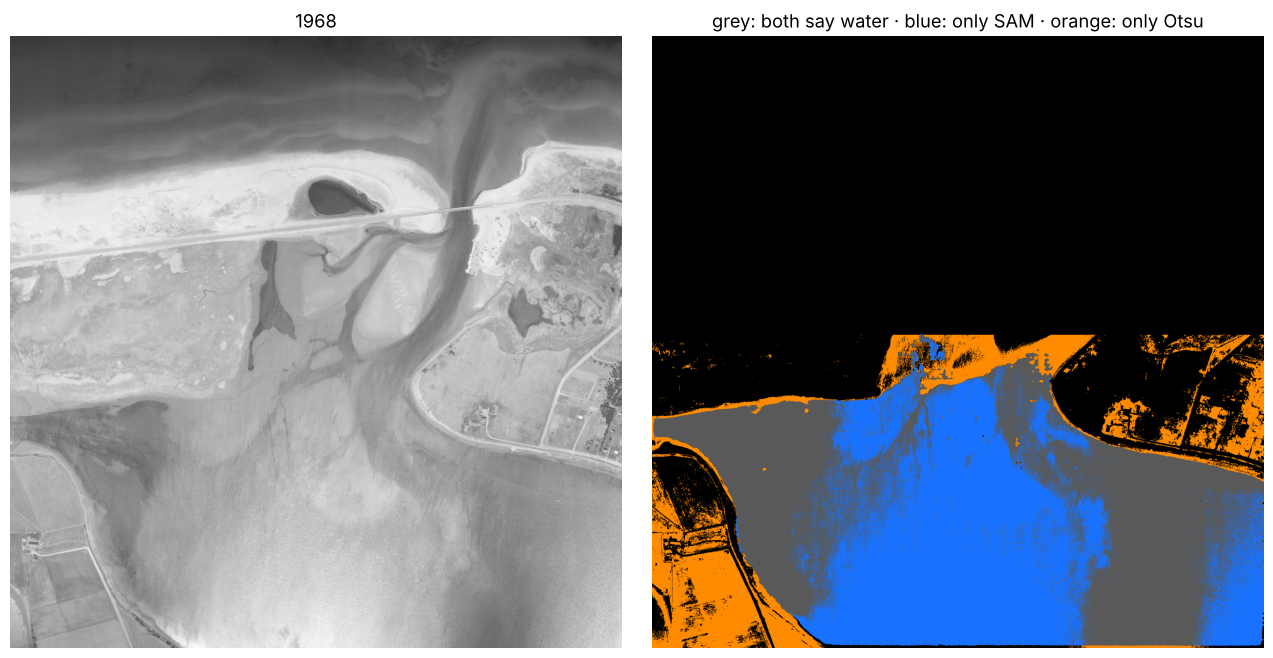

In [9]:
def iou(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)

img = TILES["coastal_covehead", 1968]
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
x1, y1, x2, y2 = BOX
inbox = np.zeros(grey.shape, bool); inbox[y1:y2, x1:x2] = True
t, _ = cv2.threshold(grey[inbox].reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
otsu = (grey < t) & inbox                                     # water is the darker class here
print(f"Otsu threshold {t:.0f}; IoU(SAM, Otsu) inside the box = {iou(WATER[1968] & inbox, otsu):.2f}")

diff = np.zeros(grey.shape + (3,))
diff[WATER[1968] & otsu] = (0.35, 0.35, 0.35)
diff[WATER[1968] & ~otsu] = (0.1, 0.45, 1.0)
diff[~WATER[1968] & otsu] = (1.0, 0.55, 0.0)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(rgb(img)); axes[0].set_title("1968")
axes[1].imshow(diff); axes[1].set_title("grey: both say water · blue: only SAM · orange: only Otsu")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

They agree on only part of the bay (IoU about 0.4). Otsu calls every dark pixel water, including the
dark fields bottom-left and on the east shore (orange), and misses the brighter (shallow or sunlit)
water in the middle of the bay (blue). SAM uses shape and context, so it avoids both mistakes here.
Where two methods disagree is where your hand-drawn check should concentrate.

**For your report:** draw 10–20 masks by hand across different years, and give SAM's IoU against them
per year. If 1935 scores much lower than 2020, say so, and say how that limits your conclusions.

## 7 · "Segment everything": counting fields, 1935 vs 2020

With no prompt at all, SAM can cut up the whole picture. Under the hood that's just **a grid of
clicks** (here 16 × 16 = 256), keeping the confident masks and throwing away duplicates, which is
L15's **non-maximum suppression**, with mask IoU instead of box IoU.

For the farm tile we shrink each image to 1024 × 1024 first (2 m per pixel; fields are big), so one
pixel is 4 m². Then we count segments of at least 0.5 ha and look at their sizes. Consolidation should
show up as **fewer, bigger** segments.

In [10]:
def segment_everything(img, step=64, min_score=0.85, nms_iou=0.5, max_frac=0.25, batch=32):
    '''Grid of single clicks every `step` px -> keep score >= min_score and smaller than max_frac of the
    image -> greedy NMS on mask IoU (best score first). Returns (masks, scores).'''
    set_image(img)
    H, W = img.shape[:2]
    grid = [[int(x), int(y)] for y in range(step // 2, H, step) for x in range(step // 2, W, step)]
    masks, scores = [], []
    for i in range(0, len(grid), batch):
        pts = grid[i:i + batch]
        r = predictor(points=pts, labels=[1] * len(pts))[0]      # flat list = one object per point
        for m, s in zip(r.masks.data.cpu().numpy().astype(bool), r.boxes.conf.cpu().numpy()):
            if s >= min_score and 0 < m.sum() < max_frac * H * W:
                masks.append(m); scores.append(float(s))
    keep = []
    for i in np.argsort(scores)[::-1]:
        if all(iou(masks[i], masks[j]) < nms_iou for j in keep):
            keep.append(i)
    return [masks[i] for i in keep], [scores[i] for i in keep]

SEGS, AREAS = {}, {}
for year in (1935, 1968, 2020):
    small = cv2.resize(TILES["farm_queen_rd", year], (1024, 1024), interpolation=cv2.INTER_AREA)
    t0 = time.time()
    SEGS[year], _ = segment_everything(small)
    a = np.array([area_ha(m, m_per_px=2.0) for m in SEGS[year]])
    AREAS[year] = a[a >= 0.5]
    covered = np.any(np.stack(SEGS[year]), 0).mean()
    print(f"{year}: {len(AREAS[year])} segments >= 0.5 ha, median {np.median(AREAS[year]):.1f} ha, "
          f"mean {AREAS[year].mean():.1f} ha, {covered:.0%} of the tile covered  ({time.time() - t0:.0f} s)")

1935: 117 segments >= 0.5 ha, median 2.0 ha, mean 2.5 ha, 70% of the tile covered  (81 s)


1968: 83 segments >= 0.5 ha, median 2.5 ha, mean 3.5 ha, 67% of the tile covered  (71 s)


2020: 62 segments >= 0.5 ha, median 2.7 ha, mean 5.5 ha, 75% of the tile covered  (66 s)


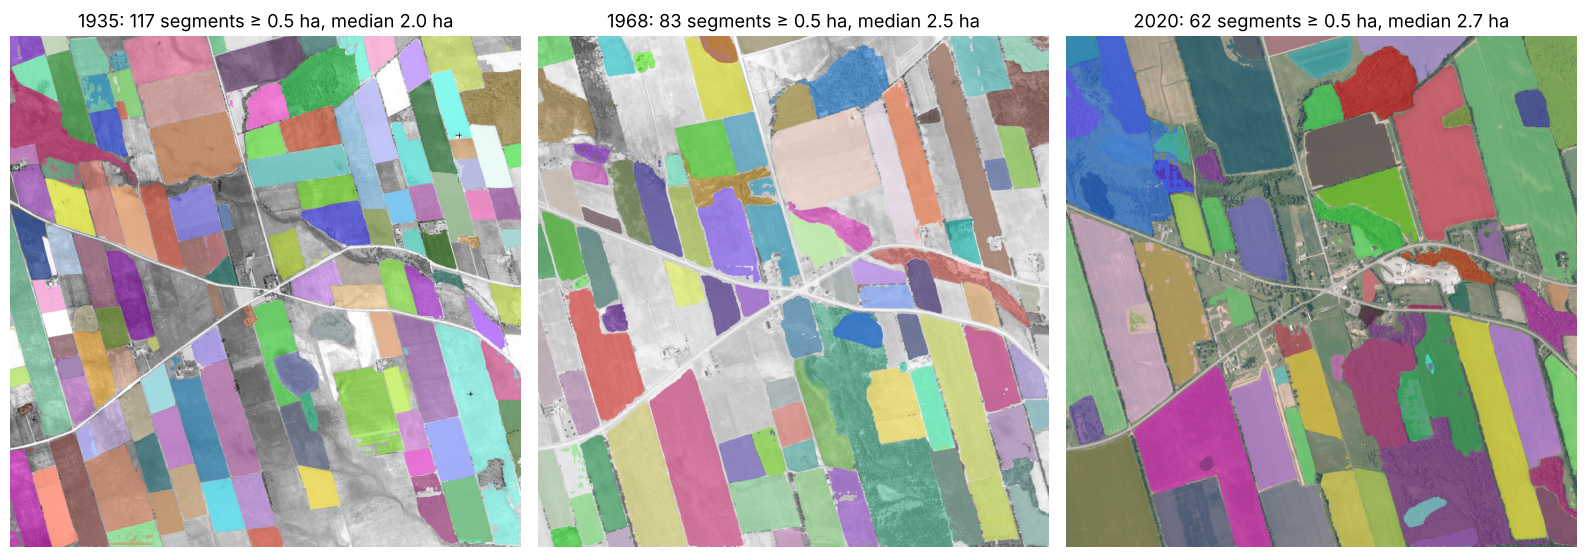

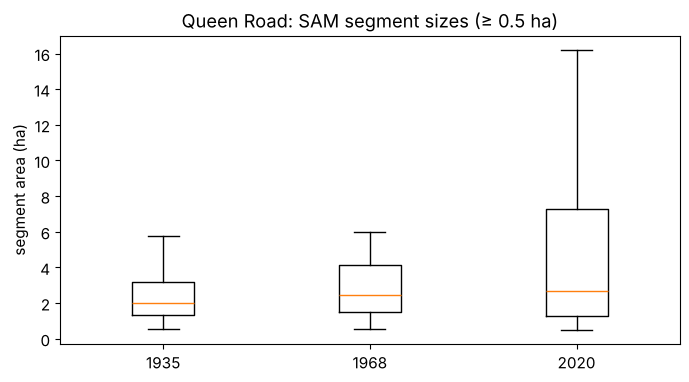

In [11]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8))
for ax, year in zip(axes, (1935, 1968, 2020)):
    small = cv2.resize(TILES["farm_queen_rd", year], (1024, 1024), interpolation=cv2.INTER_AREA)
    show = rgb(small).astype(float) / 255
    for m in SEGS[year]:
        show[m] = 0.45 * show[m] + 0.55 * rng.random(3)
    ax.imshow(show); ax.axis("off")
    ax.set_title(f"{year}: {len(AREAS[year])} segments ≥ 0.5 ha, median {np.median(AREAS[year]):.1f} ha")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
plt.boxplot([AREAS[y] for y in (1935, 1968, 2020)], showfliers=False)
plt.xticks([1, 2, 3], ["1935", "1968", "2020"]); plt.ylabel("segment area (ha)")
plt.title("Queen Road: SAM segment sizes (≥ 0.5 ha)"); plt.show()

Fewer, bigger segments each year, which is what consolidation looks like. But read the pictures
before the numbers:

* a **segment is not a field**: woodlots, ponds and farmyards are segments too, and two fields with
  the same crop can merge into one;
* uncoloured areas were **missed** (about a quarter to a third of each tile): low-contrast fields,
  especially the pale 1968 ones. Lower `min_score` or use a finer grid (`step=32`, four times slower)
  and check what you gain;
* every setting here (`step`, `min_score`, `nms_iou`, the 0.5 ha cut-off) changes the counts. Keep
  them the **same for every year** and report them.

The one-line version, `SAM("sam2.1_b.pt")(img)`, does the same thing with a 32 × 32 grid and extra
filtering; it took about 4.5 minutes per image on a CPU when this notebook was built.

## 8 · Saving masks, areas and outlines

Save masks as PNGs (white = inside) so you can re-use them, check them by eye, or compare them with
hand-drawn ones. `cv2.findContours` turns a mask into outlines (polygons) with areas and perimeters.

In [12]:
os.makedirs("sam_out", exist_ok=True)
for year, m in WATER.items():
    cv2.imwrite(f"sam_out/covehead_water_{year}.png", m.astype(np.uint8) * 255)

rows = []
for year in (1935, 1968, 2020):
    for k, m in enumerate(SEGS[year]):
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(contours, key=cv2.contourArea)                       # largest piece
        rows.append((year, k, area_ha(m, 2.0), cv2.arcLength(c, True) * 2.0, len(c)))
with open("sam_out/queen_rd_segments.csv", "w") as f:
    f.write("year,segment,area_ha,perimeter_m,polygon_vertices\n")
    f.writelines(f"{y},{k},{a:.3f},{p:.0f},{n}\n" for y, k, a, p, n in rows)
print(sorted(os.listdir("sam_out")))
print(open("sam_out/queen_rd_segments.csv").read()[:300])

['covehead_water_1935.png', 'covehead_water_1968.png', 'covehead_water_2020.png', 'queen_rd_segments.csv']
year,segment,area_ha,perimeter_m,polygon_vertices
1935,0,7.571,1161,262
1935,1,2.510,681,150
1935,2,0.680,336,57
1935,3,1.961,602,131
1935,4,1.079,422,94
1935,5,1.808,604,177
1935,6,1.410,503,92
1935,7,4.549,1046,178
1935,8,1.620,540,129
1935,9,5.564,1040,214
1935,10,1.730,560,128
1935,11,2.220,658,


**Map coordinates.** Your PNGs have no map coordinates in them, but each site's `info.txt` gives the
block centre and size on the EPSG:2954 grid (1 m pixels). Pixel (col, row) is then
`(x0 + col, y_top − row)` with `x0 = centre_x − W/2`, `y_top = centre_y + H/2` — check `info.txt` for
your site (a few coastal blocks are rotated by about 1°, which it notes).

## 9 · Practical tips

* **SAM sees every image at 1024 pixels across.** A whole 3400 × 3000 tile becomes about 3.3 m per
  pixel. That's fine for a bay or a large field, too coarse for a hedgerow or a house. For small things,
  crop first: `img[y:y+1024, x:x+1024]` keeps full 1 m detail. Add the crop's `x, y` back to any
  coordinates you measure.
* **Grey photos work** (they're copied into three channels by `load`). But 1935 contrast and exposure
  vary from print to print, so expect lower scores and check more.
* **Encode once, prompt many.** `set_image` is the slow step; reuse it for all the prompts on that
  picture.
* **Read the score**, but don't trust it alone: SAM can be confidently wrong (§3, 2020).
* **Seams, ink marks and black no-data corners** in the project tiles will be segmented like anything
  else. Mask them out or add "not this" clicks.
* **Model size:** `sam2.1_t.pt` (tiny) is quicker, `sam2.1_l.pt` (large) a little better. Try `t` while
  you set things up, `b` or `l` for final numbers, and say which you used.
* **Be consistent across years**: same prompts, same settings, same rule for what counts.
* **Check against hand-drawn masks** (§6) and report the IoU. That's what makes a SAM result a
  measurement.

## 10 · Swapping in SAM 3 (text prompts)

**SAM 3** (Meta, Nov 2025) adds **text prompts**: type `"farm field"` or `"body of water"` and it
finds every match, no clicks. It also takes the same clicks and boxes as SAM 2. Two catches:

1. **The weights are gated.** You need a Hugging Face account, then *Request access* on the
   [facebook/sam3](https://huggingface.co/facebook/sam3) page and accept the licence. Approval can
   take minutes or days, and some requests are refused without a reason. **Ask now if you want it**,
   and keep SAM 2 as your fallback. The licence doesn't allow passing the weights file to classmates:
   each person who runs it needs their own approval.
2. **It needs a GPU** (about 850 million parameters). In Colab: *Runtime → Change runtime type → T4 GPU*.

**Steps once you're approved**

1. Download `sam3.pt` from the *Files and versions* tab of the model page, and put it in your Drive
   (or upload it to the Colab session).
2. Set `SAM3_WEIGHTS` below to its path.
3. **Clicks and boxes:** the only change to everything above is the weights name: `SAM("sam3.pt")` instead
   of `SAM("sam2.1_b.pt")` (the cell below shows the call).
4. **Text:** use `SAM3SemanticPredictor` (second cell below). Text prompts also need OpenAI's CLIP
   tokenizer: `pip install git+https://github.com/ultralytics/CLIP.git`.

These cells skip themselves unless the weights file is there. **They were not run when this notebook
was built** (the course build machine has no SAM 3 approval), so treat them as a recipe, and check
the [ultralytics SAM 3 page](https://docs.ultralytics.com/models/sam-3/) if an argument name has
changed.

In [13]:
SAM3_WEIGHTS = "sam3.pt"            # e.g. "/content/drive/MyDrive/sam3.pt"

if os.path.exists(SAM3_WEIGHTS):
    from ultralytics import SAM
    sam3 = SAM(SAM3_WEIGHTS)
    img = TILES["coastal_covehead", 1935]
    r = sam3(img, bboxes=[list(BOX)], points=[[list(p) for p in PTS]], labels=[LAB], verbose=False)[0]
    m3 = r.masks.data[0].cpu().numpy().astype(bool)
    print(f"SAM 3, same prompts as §4 on 1935: {area_ha(m3):.0f} ha; IoU with SAM 2's mask {iou(m3, WATER[1935]):.2f}")
else:
    print(f"{SAM3_WEIGHTS} not found: skipping SAM 3 (see the steps above).")

sam3.pt not found: skipping SAM 3 (see the steps above).


In [14]:
if os.path.exists(SAM3_WEIGHTS):
    from ultralytics.models.sam import SAM3SemanticPredictor
    text_predictor = SAM3SemanticPredictor(overrides=dict(model=SAM3_WEIGHTS, task="segment", mode="predict",
                                                          conf=0.25, save=False,
                                                          verbose=False))
    for site, year, prompts in [("farm_queen_rd", 1935, ["farm field", "forest"]),
                                ("coastal_covehead", 2020, ["water", "sand bar"])]:
        img = TILES[site, year]
        text_predictor.set_image(img)
        r = text_predictor(text=prompts)[0]
        n = 0 if r.masks is None else len(r.masks)
        print(f"{site} {year} {prompts}: {n} masks")
        if n:
            fig, ax = plt.subplots(figsize=(7, 7))
            show = rgb(img).astype(float) / 255
            for m in r.masks.data.cpu().numpy().astype(bool):
                show[m] = 0.45 * show[m] + 0.55 * np.random.rand(3)
            ax.imshow(show); ax.axis("off"); ax.set_title(f"SAM 3 text prompts {prompts}")
            plt.show()
else:
    print("no SAM 3 weights: skipping text prompts.")

no SAM 3 weights: skipping text prompts.


**Is SAM 3 better on 1935 photos?** Nobody knows yet for these images: its published results are on
modern colour aerial imagery. If you get access, run §4–§7 with both models and compare with your
hand-drawn masks (§6). That comparison is a good paragraph for a final report.

Coming up in the course: **L16** (segmentation: FCN, U-Net, Mask R-CNN) and **AL10**, which
will use this notebook's tools on the project tiles.